# Image Processing: Load and Convert to Grayscale

This notebook demonstrates loading the image `photo-1550853024-fae8cd4be47f.avif`, converting it to grayscale using `PIL` and `pillow-heif`, and displaying the results with `matplotlib`.

In [ ]:
import pillow_heif
from PIL import Image
import matplotlib.pyplot as plt

# Register AVIF/HEIF opener with Pillow
pillow_heif.register_heif_opener()

Image size: (3000, 2961)
Color mode: RGB


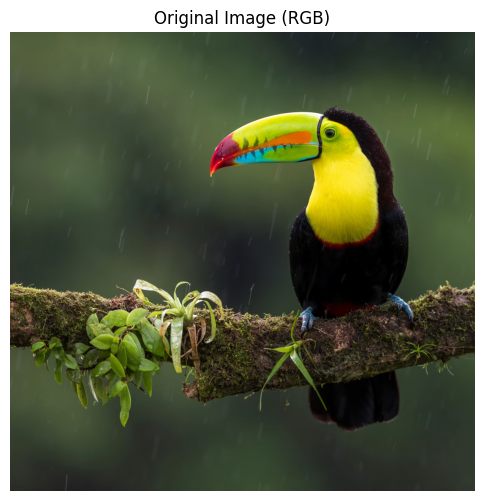

In [ ]:
# Load the original image
image_path = "photo-1550853024-fae8cd4be47f.avif"
img_rgb = Image.open(image_path)

print(f"Image size: {img_rgb.size}")
print(f"Color mode: {img_rgb.mode}")

# Display the original image
plt.figure(figsize=(6, 6))
plt.imshow(img_rgb)
plt.title("Original Image (RGB)")
plt.axis("off")
plt.show()

Grayscale size: (3000, 2961)
Grayscale mode: L


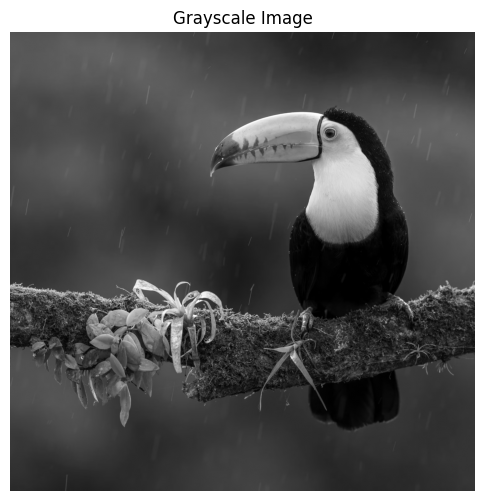

In [ ]:
# Convert image to grayscale
img_gray = img_rgb.convert("L")

print(f"Grayscale size: {img_gray.size}")
print(f"Grayscale mode: {img_gray.mode}")

# Display the grayscale image
plt.figure(figsize=(6, 6))
plt.imshow(img_gray, cmap="gray")
plt.title("Grayscale Image")
plt.axis("off")
plt.show()

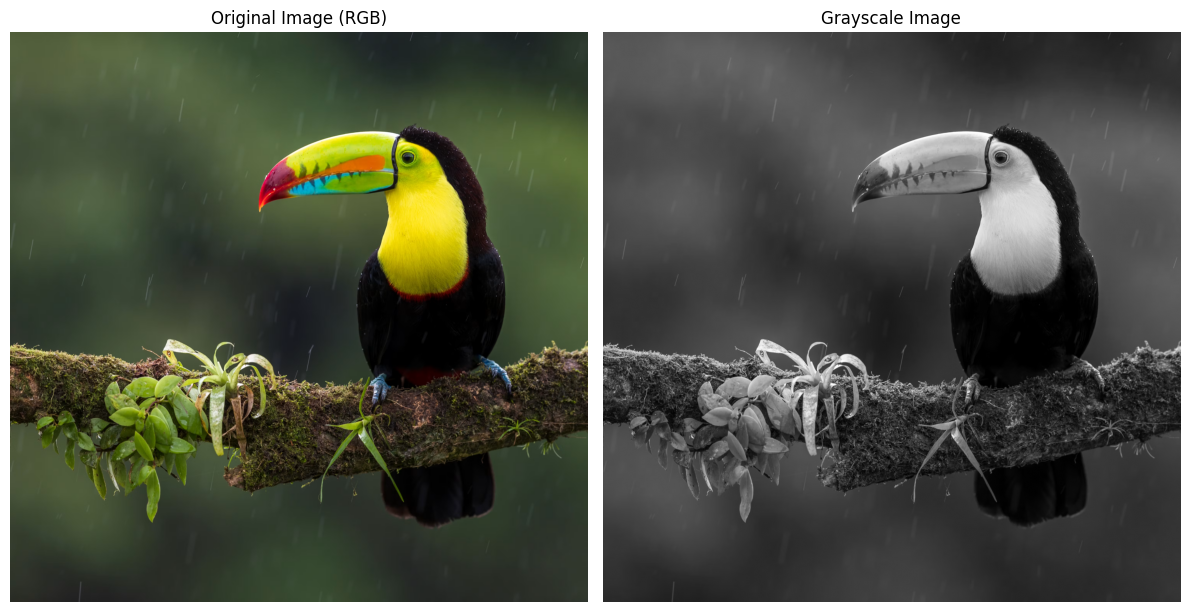

In [ ]:
# Side-by-side comparison
fig, axes = plt.subplots(1, 2, figsize=(12, 6))

axes[0].imshow(img_rgb)
axes[0].set_title("Original Image (RGB)")
axes[0].axis("off")

axes[1].imshow(img_gray, cmap="gray")
axes[1].set_title("Grayscale Image")
axes[1].axis("off")

plt.tight_layout()
plt.show()

In [ ]:
# Optional: Save the grayscale image as PNG
img_gray.save("photo_grayscale.png")
print("Grayscale image saved as photo_grayscale.png")

Grayscale image saved as photo_grayscale.png


## Part 2: SVD Image Compression (Rank-$r$ Approximation)

We perform **Singular Value Decomposition (SVD)** on the grayscale matrix $A$:
$$A = U \Sigma V^T = \sum_{i=1}^{\min(m, n)} \sigma_i u_i v_i^T$$

and reconstruct low-rank approximations keeping only the top $r$ singular values:
$$A_r = U_r \Sigma_r V_r^T = \sum_{i=1}^{r} \sigma_i u_i v_i^T$$
- **Original storage**: $m \times n$ numbers
- **Rank-$r$ storage**: $r(m + n + 1)$ numbers (columns of $U$, diagonal of $\Sigma$, rows of $V^T$)
- **Compression Ratio**: $\frac{r(m + n + 1)}{m \times n}$

In [ ]:
import numpy as np

# 1. Convert the grayscale image into a 2D numpy array A
A = np.array(img_gray, dtype=np.float64)
m, n = A.shape

print(f"Grayscale matrix dimensions: {m} x {n}")
print(f"Total uncompressed elements: {m * n:,} numbers")

Grayscale matrix dimensions: 2961 x 3000
Total uncompressed elements: 8,883,000 numbers


In [ ]:
# 2. Compute the Singular Value Decomposition (SVD)
U, S, Vt = np.linalg.svd(A, full_matrices=False)

print(f"Shape of U  (left singular vectors) : {U.shape}")
print(f"Shape of S  (singular values)        : {S.shape} ({len(S)} total)")
print(f"Shape of Vt (right singular vectors) : {Vt.shape}")

Shape of U  (left singular vectors) : (2961, 2961)
Shape of S  (singular values)        : (2961,) (2961 total)
Shape of Vt (right singular vectors) : (2961, 3000)


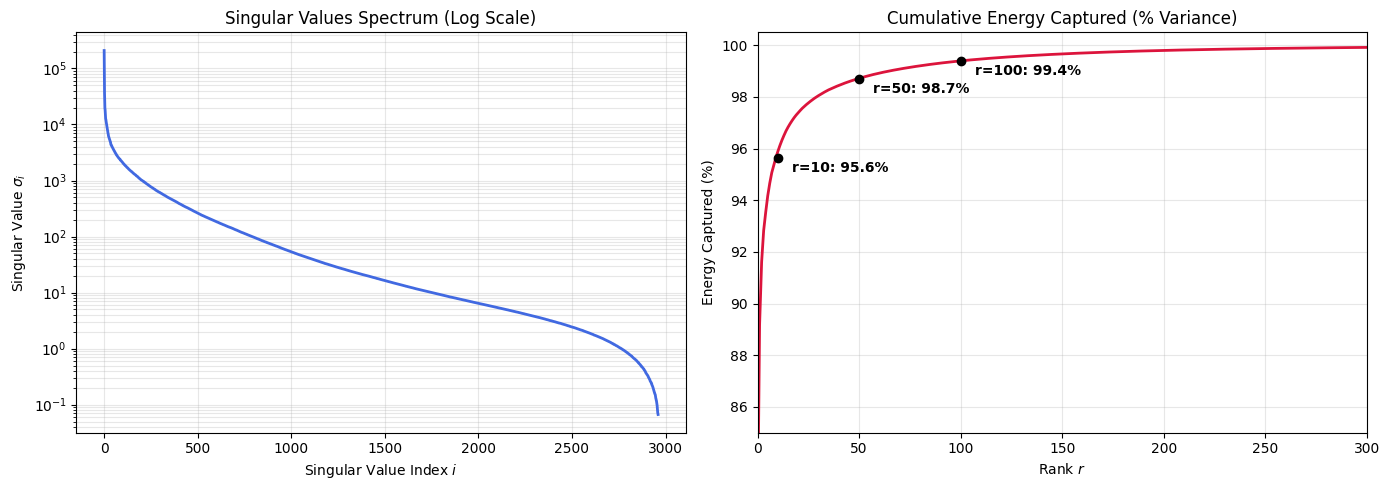

In [ ]:
# 3. Plot Singular Values Decay (Log Scale) & Cumulative Energy Captured
cumulative_energy = np.cumsum(S**2) / np.sum(S**2) * 100

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Singular values decay (log scale)
ax1.semilogy(S, color="royalblue", lw=2)
ax1.set_title("Singular Values Spectrum (Log Scale)")
ax1.set_xlabel("Singular Value Index $i$")
ax1.set_ylabel(r"Singular Value $\sigma_i$")
ax1.grid(True, which="both", alpha=0.3)

# Cumulative energy percentage
ax2.plot(cumulative_energy, color="crimson", lw=2)
for r_val in [10, 50, 100]:
    energy_at_r = cumulative_energy[r_val - 1]
    ax2.plot(r_val, energy_at_r, "ko")
    ax2.annotate(f"r={r_val}: {energy_at_r:.1f}%", (r_val, energy_at_r),
                 textcoords="offset points", xytext=(10, -10), fontweight="bold")

ax2.set_title("Cumulative Energy Captured (% Variance)")
ax2.set_xlabel("Rank $r$")
ax2.set_ylabel("Energy Captured (%)")
ax2.set_xlim(0, 300)
ax2.set_ylim(85, 100.5)
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [14]:
# 4. Define function for rank-r compression
def compress_image_svd(U, S, Vt, r):
    """
    Reconstructs rank-r approximation using the top r singular values.
    """
    # A_r = U_r * S_r * Vt_r
    A_r = (U[:, :r] * S[:r]) @ Vt[:r, :]
    A_r = np.clip(A_r, 0, 255)
    
    # Compute metrics
    rel_error = (np.linalg.norm(A - A_r) / np.linalg.norm(A)) * 100
    stored_elements = r * (m + n + 1)
    storage_ratio = (stored_elements / (m * n)) * 100
    energy = (np.sum(S[:r]**2) / np.sum(S**2)) * 100
    
    return A_r, rel_error, storage_ratio, energy

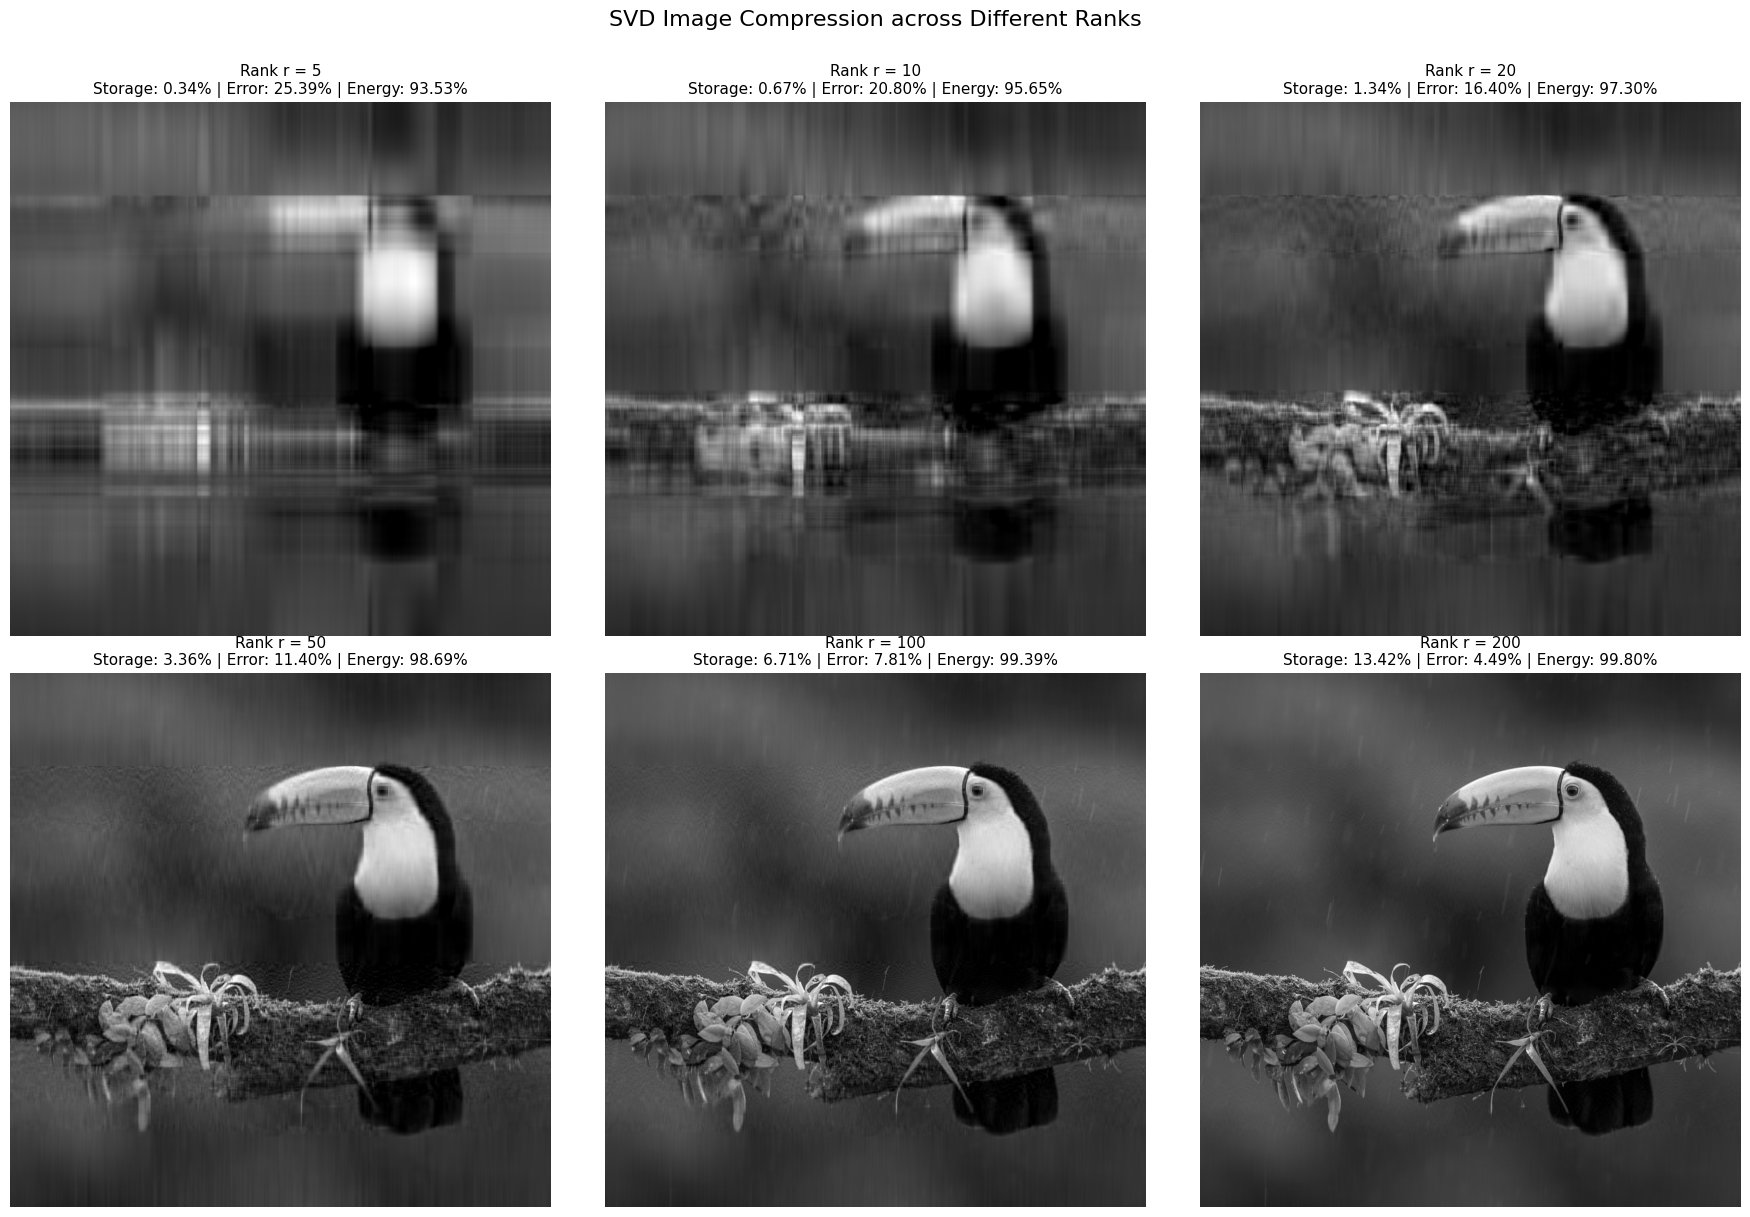

In [15]:
# 5. Visual Comparison across different ranks (r = 5, 10, 20, 50, 100, 200)
ranks = [5, 10, 20, 50, 100, 200]

fig, axes = plt.subplots(2, 3, figsize=(18, 12))
axes = axes.flatten()

for i, r in enumerate(ranks):
    A_r, rel_error, storage_ratio, energy = compress_image_svd(U, S, Vt, r)
    
    axes[i].imshow(A_r, cmap="gray")
    axes[i].set_title(f"Rank r = {r}\nStorage: {storage_ratio:.2f}% | Error: {rel_error:.2f}% | Energy: {energy:.2f}%", fontsize=11)
    axes[i].axis("off")

plt.suptitle("SVD Image Compression across Different Ranks", fontsize=16, y=1.01)
plt.tight_layout()
plt.show()

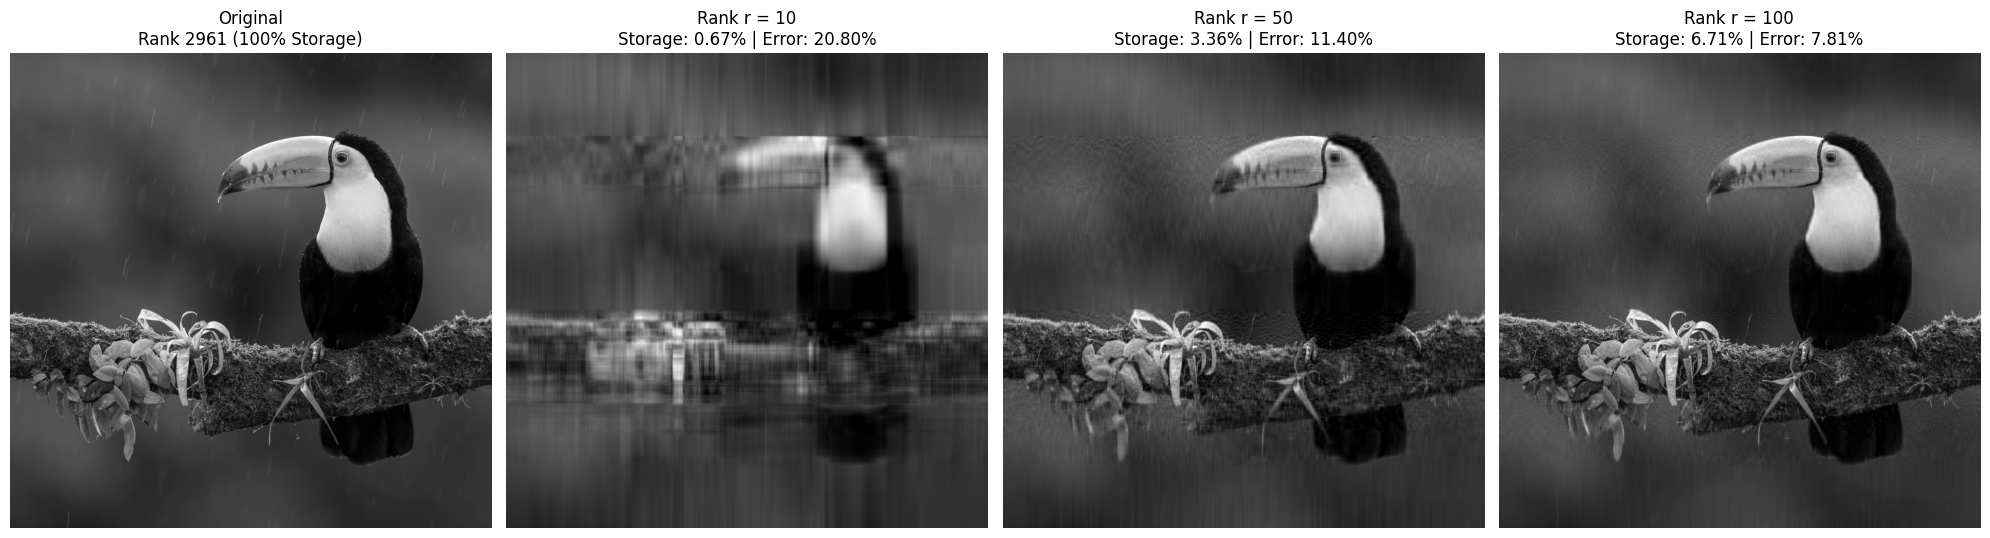

In [16]:
# 6. Direct Side-by-Side: Original vs r = 10, r = 50, r = 100
selected_ranks = [10, 50, 100]

fig, axes = plt.subplots(1, 4, figsize=(20, 6))

# Original
axes[0].imshow(A, cmap="gray")
axes[0].set_title(f"Original\nRank {min(m, n)} (100% Storage)", fontsize=12)
axes[0].axis("off")

# Approximations
for idx, r in enumerate(selected_ranks, start=1):
    A_r, rel_err, stor_pct, nrg = compress_image_svd(U, S, Vt, r)
    axes[idx].imshow(A_r, cmap="gray")
    axes[idx].set_title(f"Rank r = {r}\nStorage: {stor_pct:.2f}% | Error: {rel_err:.2f}%", fontsize=12)
    axes[idx].axis("off")

plt.tight_layout()
plt.show()

In [17]:
# 7. Quantitative Metrics Summary Table
print("=" * 75)
print(f"{'Rank (r)':<10} {'Stored Numbers':<18} {'Storage (%)':<14} {'Energy (%)':<14} {'Rel Error (%)':<14}")
print("=" * 75)

for r in [5, 10, 20, 50, 100, 200, 500]:
    _, rel_error, storage_ratio, energy = compress_image_svd(U, S, Vt, r)
    stored = r * (m + n + 1)
    print(f"{r:<10d} {stored:<18,d} {storage_ratio:<14.2f} {energy:<14.2f} {rel_error:<14.2f}")

print("=" * 75)
print(f"{'Original':<10} {m * n:<18,d} {'100.00':<14} {'100.00':<14} {'0.00':<14}")
print("=" * 75)

Rank (r)   Stored Numbers     Storage (%)    Energy (%)     Rel Error (%) 
5          29,810             0.34           93.53          25.39         
10         59,620             0.67           95.65          20.80         
20         119,240            1.34           97.30          16.40         
50         298,100            3.36           98.69          11.40         
100        596,200            6.71           99.39          7.81          
200        1,192,400          13.42          99.80          4.49          
500        2,981,000          33.56          99.98          1.39          
Original   8,883,000          100.00         100.00         0.00          
